# 6.1 Свободный полёт и выбор события

# 6.1 自由飞行与事件选择

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})

## Экспоненциальное время
При постоянной частоте $\Gamma=1/\tau$ вероятность не встретить событие до времени $t$ равна $e^{-t/\tau}$. Единица времени в этом примере условная.

## 指数分布的飞行时间
恒定事件率 $\Gamma=1/\tau$ 下，到时间 $t$ 尚未发生事件的概率为 $e^{-t/\tau}$。本例使用任意时间单位。

In [2]:
rng = np.random.default_rng(42)
tau = 2.0
N = 100_000
u = rng.random(N)
flight = -tau * np.log1p(-u)
flight_builtin = rng.exponential(tau, N)
print(f"Обратная функция / 逆变换: mean={flight.mean():.5f}")
print(f"NumPy: mean={flight_builtin.mean():.5f}; theory={tau:.5f}")

Обратная функция / 逆变换: mean=2.00280
NumPy: mean=1.99218; theory=2.00000


`random` выдаёт $u\in[0,1)$. Запись $-\tau\ln(1-u)$ исключает логарифм нуля. `exponential(tau, ...)` использует тот же закон, но выдаёт другую выборку.

`random` 生成 $u\in[0,1)$，采用 $-\tau\ln(1-u)$ 可避免计算零的对数。`exponential(tau, ...)` 服从同一分布，但生成另一组样本。

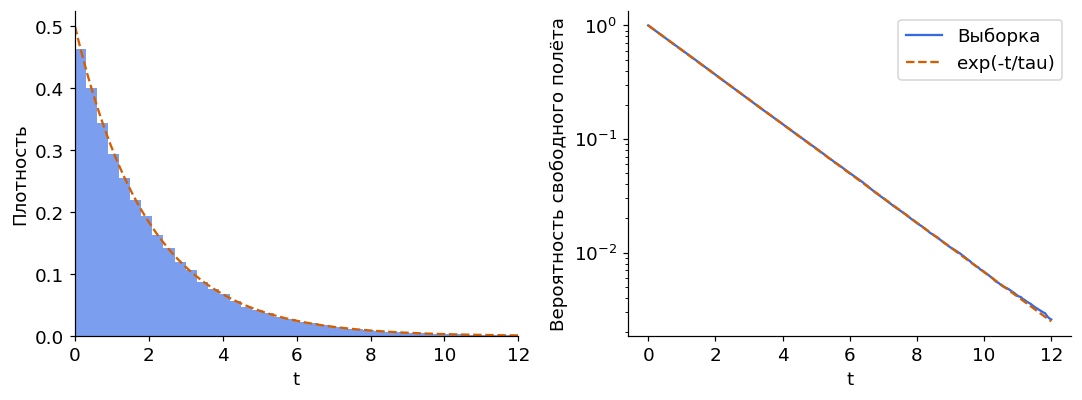

In [3]:
grid = np.linspace(0, 6 * tau, 200)
empirical_survival = 1 - np.searchsorted(np.sort(flight), grid, side="right") / N
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(flight, bins=80, density=True, alpha=0.65)
axes[0].plot(grid, np.exp(-grid / tau) / tau, "--", color="#D55E00")
axes[0].set(xlabel="t", ylabel="Плотность", xlim=(0, 6 * tau))
axes[1].semilogy(grid, empirical_survival, label="Выборка")
axes[1].semilogy(grid, np.exp(-grid / tau), "--", label="exp(-t/tau)")
axes[1].set(xlabel="t", ylabel="Вероятность свободного полёта")
axes[1].legend()
fig.tight_layout()
plt.show()

## Конкурирующие процессы
Для постоянных независимых частот общая частота равна их сумме. Время и тип события выбираем независимо. Названия процессов здесь условные.

## 竞争过程
各个独立过程的频率恒定时，总频率等于各过程频率之和。独立选择事件时间和事件类型，这里的过程名称为示意标签。

P theory: [0.2 0.3 0.5]
P MC:     [0.2006  0.30066 0.49874]
mean(t)=0.99777


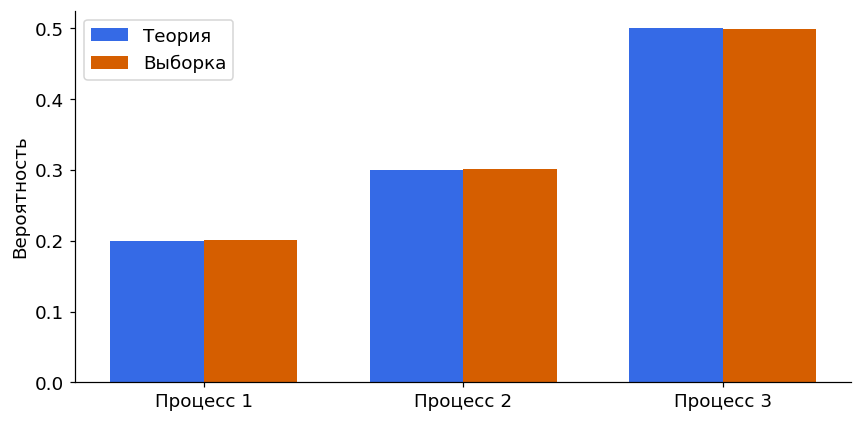

In [4]:
rates = np.array([0.2, 0.3, 0.5])
probabilities = rates / rates.sum()
event_time = rng.exponential(1 / rates.sum(), N)
event_type = rng.choice(3, size=N, p=probabilities)
frequencies = np.bincount(event_type, minlength=3) / N
print("P theory:", probabilities)
print("P MC:    ", frequencies)
print(f"mean(t)={event_time.mean():.5f}")
fig, ax = plt.subplots()
labels = np.arange(3)
ax.bar(labels - 0.18, probabilities, width=0.36, label="Теория")
ax.bar(labels + 0.18, frequencies, width=0.36, label="Выборка")
ax.set(xticks=labels, xticklabels=["Процесс 1", "Процесс 2", "Процесс 3"], ylabel="Вероятность")
ax.legend()
fig.tight_layout()
plt.show()

## Не менее одного события и несколько событий
При $h=\Delta t/\tau$ величина $1-e^{-h}$ является точной вероятностью хотя бы одного события. Если алгоритм выполняет только одно рассеяние в конце шага, моменты и число событий внутри шага теряются.

## 至少一次事件与多次事件
令 $h=\Delta t/\tau$，则 $1-e^{-h}$ 是至少发生一次事件的精确概率。如果算法只在步末执行一次散射，就忽略了步内的事件时刻和事件次数。

In [5]:
h = np.array([0.05, 0.1, 0.5, 1.0])
p_at_least_one = -np.expm1(-h)
p_two_or_more = 1 - np.exp(-h) * (1 + h)
for step_size, p1, p2 in zip(h, p_at_least_one, p_two_or_more):
    print(f"dt/tau={step_size:.2f}: P(>=1)={p1:.5f}, P(>=2)={p2:.5f}")

dt/tau=0.05: P(>=1)=0.04877, P(>=2)=0.00121
dt/tau=0.10: P(>=1)=0.09516, P(>=2)=0.00468
dt/tau=0.50: P(>=1)=0.39347, P(>=2)=0.09020
dt/tau=1.00: P(>=1)=0.63212, P(>=2)=0.26424


## Попробуйте
Измените $\tau$ и частоты процессов. Сравните среднее время и доли событий с теорией.

Документация: [NumPy Generator.exponential](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.exponential.html).

## 练习
修改 $\tau$ 和各过程频率，比较平均时间及各类事件比例与理论值。

文档：[NumPy Generator.exponential](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.exponential.html)。